<a href="https://colab.research.google.com/github/baynobu/pembelajaran-mesin-26/blob/main/TG7_244107020232_Abdul_Rahman_Hanif_D_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JOBSHEET 07: REGRESI


In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Konfigurasi base path dataset di Google Drive
BASE_PATH = '/content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset'
print(f"Direktori dataset: {BASE_PATH}")

Direktori dataset: /content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset


---
# BAGIAN 1: PRAKTIKUM 1 - REGRESI LINIER SEDERHANA


## Langkah 1: Persiapan Data & Penentuan Path Dataset
Mendefinisikan path dataset sesuai dengan struktur direktori Google Drive.

In [3]:
# Menentukan path dataset di Google Drive
file_path_p1 = f"{BASE_PATH}/dataset.csv"
print(f"Path dataset Praktikum 1: {file_path_p1}")

Path dataset Praktikum 1: /content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/dataset.csv


## Langkah 2: Import Library
Mengimpor library yang diperlukan untuk manipulasi data, visualisasi, dan pemodelan statistik.

In [4]:
# Import package dan library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

## Langkah 3: Baca Data
Membaca dataset dari file CSV ke dalam DataFrame Pandas.

In [5]:
# Baca data dari file CSV
data = pd.read_csv(file_path_p1)
data.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


## Langkah 4: Pemahaman Terhadap Data (Exploratory Data Analysis)
Mengecek dimensi dataset, tipe data kolom, missing value, dan ringkasan statistik deskriptif.

In [6]:
# Mengecek dimensi data
print("Dimensi Data (baris, kolom):", data.shape)

# Informasi tipe data dan non-null values
data.info()

Dimensi Data (baris, kolom): (500, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [7]:
# Deskripsi statistik data
data.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


## Langkah 5: Visualisasi Data
Memvisualisasikan hubungan antar variabel fitur dengan variabel target, serta melihat matriks korelasi.

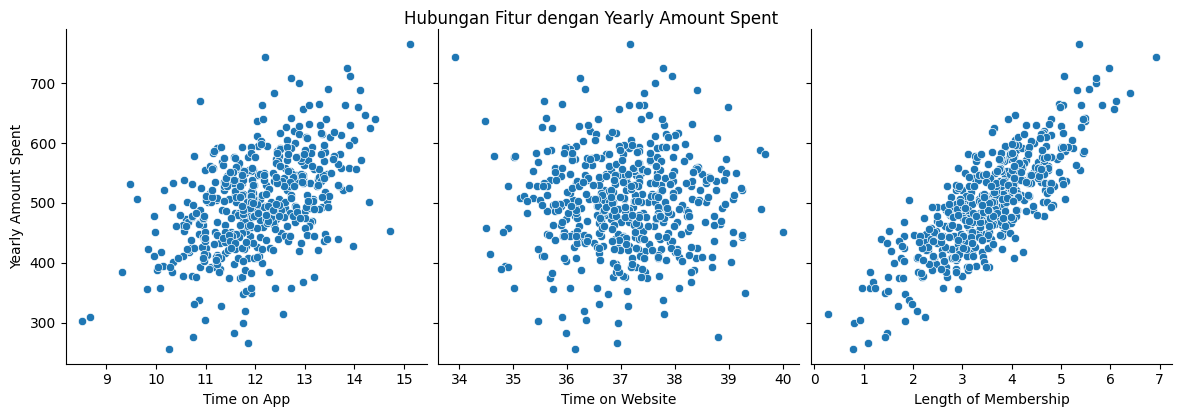

In [8]:
# Visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', height=4, aspect=1, kind='scatter')
plt.suptitle('Hubungan Fitur dengan Yearly Amount Spent', y=1.02)
plt.show()

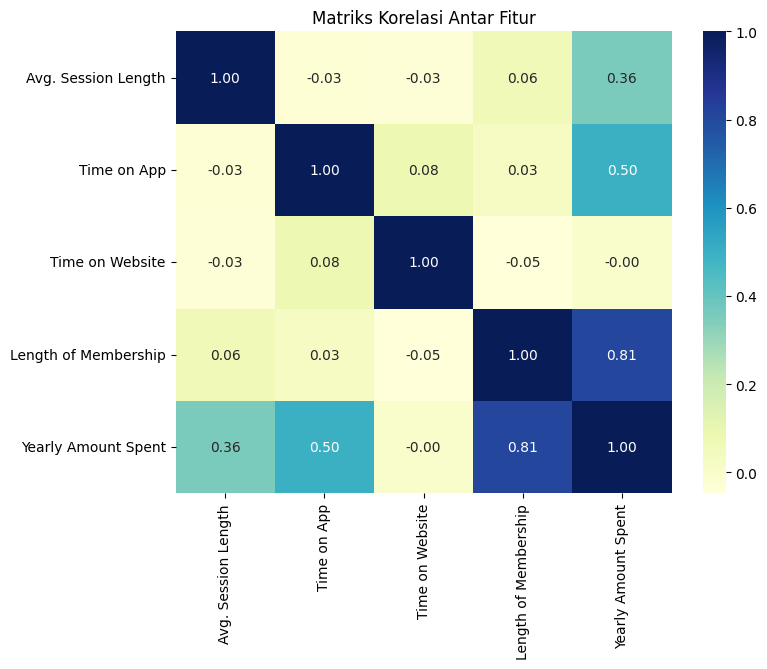

In [9]:
# Visualisasi korelasi dengan heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True, fmt=".2f")
plt.title('Matriks Korelasi Antar Fitur')
plt.show()

Berdasarkan heatmap di atas, fitur **Length of Membership** memiliki korelasi tertinggi dengan **Yearly Amount Spent** (sebesar ~0.81), sehingga dipilih sebagai variabel bebas utama (X).

## Langkah 6: Regresi Linier
Membagi variabel bebas (X) dan target (y), membagi data latih dan uji, lalu melatih model regresi linier menggunakan Statsmodels OLS.

In [10]:
# Membuat variabel bebas X dan Y
X = data['Length of Membership']
y = data['Yearly Amount Spent']

# Pembagian data latih dan data uji dengan proporsi 70% train dan 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

print(f"Jumlah data train: {len(X_train)}")
print(f"Jumlah data test : {len(X_test)}")

Jumlah data train: 350
Jumlah data test : 150


In [11]:
# Training model regresi linier dengan Statsmodels OLS
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

# Menampilkan ringkasan hasil regresi
print(lr.summary())

                             OLS Regression Results                            
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Wed, 21 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         14:58:17   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

/tmp/ipykernel_4268/535504008.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(X_train, lr.params[0] + lr.params[1] * X_train, 'r', label=f'Garis Regresi: y = {lr.params[0]:.2f} + {lr.params[1]:.2f}X')


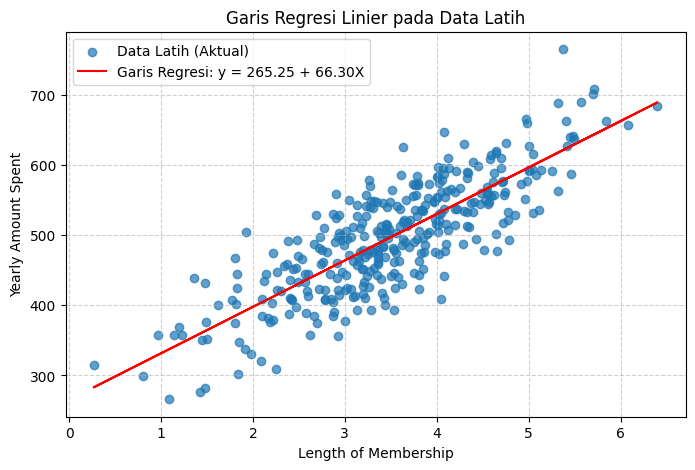

In [12]:
# Visualisasi garis regresi pada data latih
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label='Data Latih (Aktual)', alpha=0.7)
plt.plot(X_train, lr.params[0] + lr.params[1] * X_train, 'r', label=f'Garis Regresi: y = {lr.params[0]:.2f} + {lr.params[1]:.2f}X')
plt.title('Garis Regresi Linier pada Data Latih')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Langkah 7: Analisis Residual
Menganalisis residual (selisih antara nilai aktual dan prediksi pada data latih) untuk memastikan asumsi normalitas dan homoskedastisitas terpenuhi.

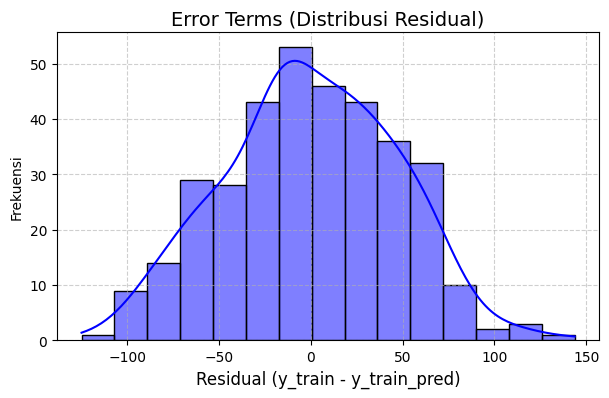

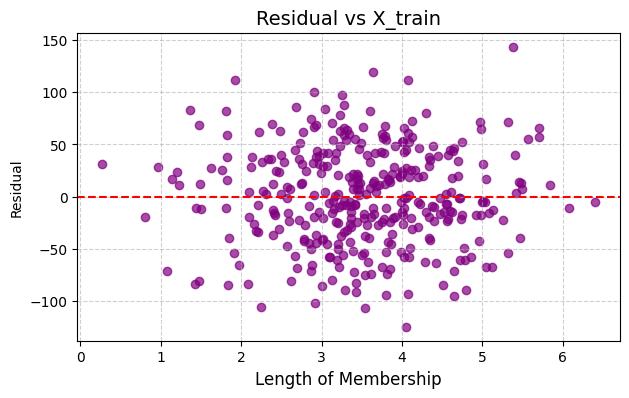

In [13]:
# Prediksi nilai y dari data latih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

# Histogram residual
plt.figure(figsize=(7, 4))
sns.histplot(res, bins=15, kde=True, color='blue')
plt.title('Error Terms (Distribusi Residual)', fontsize=14)
plt.xlabel('Residual (y_train - y_train_pred)', fontsize=12)
plt.ylabel('Frekuensi')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Scatter plot residual terhadap X_train
plt.figure(figsize=(7, 4))
plt.scatter(X_train, res, color='purple', alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residual vs X_train', fontsize=14)
plt.xlabel('Length of Membership', fontsize=12)
plt.ylabel('Residual')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Langkah 8: Prediksi pada Data Uji dan Evaluasi Model
Melakukan prediksi pada data uji ($X_{test}$) dan menghitung metrik performa $R^2$ (*R-squared*).

In [14]:
# Menambahkan konstanta pada data uji
X_test_sm = sm.add_constant(X_test)

# Prediksi pada data uji
y_test_pred = lr.predict(X_test_sm)

# Hitung nilai R-squared
r_squared = r2_score(y_test, y_test_pred)
print(f"R-squared pada Data Uji: {r_squared:.4f}")

R-squared pada Data Uji: 0.6119


## Langkah 9: Visualisasi Hasil pada Data Uji
Memvisualisasikan titik-titik data uji beserta garis hasil prediksi regresi linier.

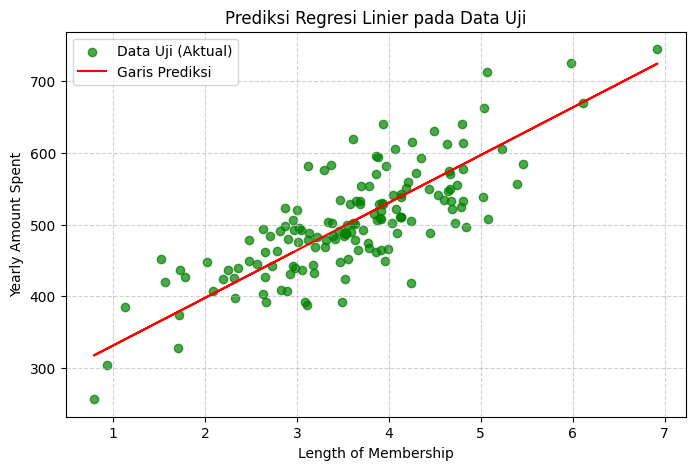

In [15]:
# Visualisasi data uji dan hasil prediksi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, label='Data Uji (Aktual)', color='green', alpha=0.7)
plt.plot(X_test, y_test_pred, 'r', label='Garis Prediksi')
plt.title('Prediksi Regresi Linier pada Data Uji')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Kesimpulan Praktikum 1:
1. Hubungan antara **Length of Membership** dan **Yearly Amount Spent** adalah linier positif yang sangat kuat.
2. Model regresi linier menghasilkan nilai $R^2$ yang tinggi pada data uji, menunjukkan bahwa variasi durasi keanggotaan mampu menjelaskan sebagian besar variasi pengeluaran tahunan pengguna.
3. Analisis residual menunjukkan bahwa galat (error) berdistribusi normal di sekitar nilai 0 tanpa pola heteroskedastisitas yang jelas.

---
# BAGIAN 2: PRAKTIKUM 2 - SUPPORT VECTOR REGRESSION (SVR)

## Langkah 1: Mengimpor Library
Mengimpor library yang diperlukan: NumPy, Matplotlib, Pandas, Scikit-Learn (StandardScaler, SVR, dan metrik evaluasi).

In [16]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Langkah 2: Mengimpor Dataset
Membaca dataset `Posisi_gaji.csv` dari Google Drive dan memilih variabel independen ($X$) dan dependen ($y$).

In [17]:
# Path dataset Praktikum 2 di Google Drive
file_path_p2 = f"{BASE_PATH}/Posisi_gaji.csv"

# Mengimpor dataset
dataset = pd.read_csv(file_path_p2)
print("Tampilan Dataset:")
display(dataset)

# Menentukan fitur X (kolom Level) dan target y (kolom Gaji)
X = dataset.iloc[:, 1:2].values  # Kolom Level (indeks 1)
y = dataset.iloc[:, 2].values    # Kolom Gaji (indeks 2)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Tampilan Dataset:


,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000



X shape: (10, 1)
y shape: (10,)


## Langkah 3: Feature Scaling
Melakukan penskalaan data menggunakan `StandardScaler` untuk fitur $X$ dan target $y$. Penskalaan sangat esensial pada SVR karena algoritma ini berbasis jarak (distance-based).

In [18]:
# Feature Scaling menggunakan StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()

X_scaled = sc_X.fit_transform(X.reshape(-1, 1))
y_scaled = sc_y.fit_transform(y.reshape(-1, 1))

print("X setelah scaling (5 data pertama):\n", X_scaled[:5])
print("\ny setelah scaling (5 data pertama):\n", y_scaled[:5])

X setelah scaling (5 data pertama):
 [[-1.5666989 ]
 [-1.21854359]
 [-0.87038828]
 [-0.52223297]
 [-0.17407766]]

y setelah scaling (5 data pertama):
 [[-0.72004253]
 [-0.70243757]
 [-0.66722767]
 [-0.59680786]
 [-0.49117815]]


## Langkah 4: Fitting SVR ke Dataset
Membuat model SVR dengan kernel Radial Basis Function (`rbf`) dan melatihnya dengan data yang telah distandardisasi.

In [19]:
# Fitting SVR ke dataset
regressor = SVR(kernel='rbf')
regressor.fit(X_scaled, y_scaled.ravel())
print("Model SVR berhasil dilatih:")
print(regressor)

Model SVR berhasil dilatih:
SVR()


## Langkah 5: Visualisasi Hasil SVR
Memvisualisasikan hasil fitting kurva SVR dengan resolusi tinggi (grid interval 0.01) pada skala hasil standardisasi.

/tmp/ipykernel_4268/3130337514.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X_scaled), max(X_scaled), 0.01).reshape(-1, 1)


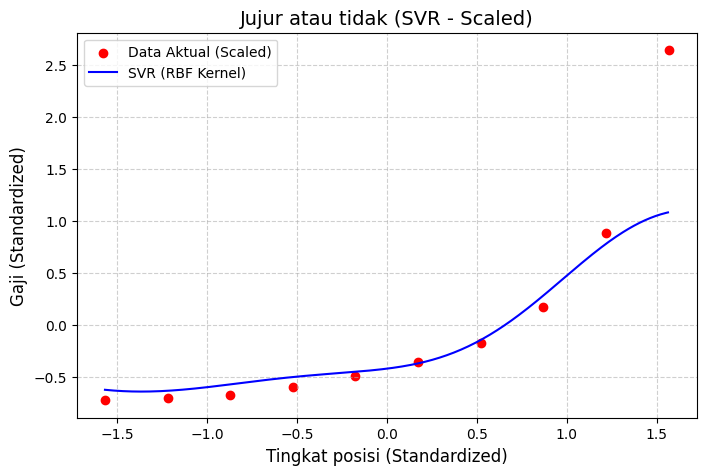

In [20]:
# Visualisasi hasil SVR (pada skala standar)
X_grid = np.arange(min(X_scaled), max(X_scaled), 0.01).reshape(-1, 1)

plt.figure(figsize=(8, 5))
plt.scatter(X_scaled, y_scaled, color='red', label='Data Aktual (Scaled)')
plt.plot(X_grid, regressor.predict(X_grid), color='blue', label='SVR (RBF Kernel)')
plt.title('Jujur atau tidak (SVR - Scaled)', fontsize=14)
plt.xlabel('Tingkat posisi (Standardized)', fontsize=12)
plt.ylabel('Gaji (Standardized)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

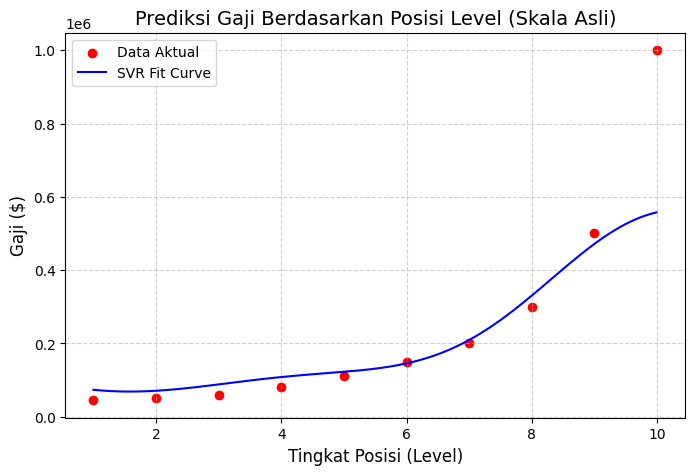

In [21]:
# Visualisasi hasil SVR dikembalikan ke Skala Asli (Rupiah / Dolar Asli)
X_grid_orig = sc_X.inverse_transform(X_grid)
y_grid_pred_orig = sc_y.inverse_transform(regressor.predict(X_grid).reshape(-1, 1))

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='red', label='Data Aktual')
plt.plot(X_grid_orig, y_grid_pred_orig, color='blue', label='SVR Fit Curve')
plt.title('Prediksi Gaji Berdasarkan Posisi Level (Skala Asli)', fontsize=14)
plt.xlabel('Tingkat Posisi (Level)', fontsize=12)
plt.ylabel('Gaji ($)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Langkah 6: Prediksi Nilai Baru (Contoh: Tingkat Posisi 6.5)

In [22]:
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])

# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_scaled = sc_X.transform(tingkat_posisi_prediksi)

# Melakukan prediksi menggunakan model SVR
gaji_prediksi_scaled = regressor.predict(tingkat_posisi_scaled)

# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi_scaled.reshape(-1, 1))

print("Tingkat Posisi Input            : 6.5")
print(f"Prediksi Gaji untuk Tingkat 6.5 : ${gaji_prediksi[0][0]:,.2f}")

Tingkat Posisi Input            : 6.5
Prediksi Gaji untuk Tingkat 6.5 : $170,370.02


## Langkah 7: Evaluasi Model SVR
Mengevaluasi performa model SVR menggunakan metrik MAE, MSE, RMSE, dan $R^2$ (*R-squared*).

In [23]:
# Evaluasi model
y_actual = y_scaled.ravel()
y_pred = regressor.predict(X_scaled)

# Menghitung metrik pada data scaled
mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print("--- Hasil Evaluasi SVR (Scaled Scale) ---")
print(f"MAE       : {mae:.6f}")
print(f"MSE       : {mse:.6f}")
print(f"RMSE      : {rmse:.6f}")
print(f"R-squared : {r2:.6f}")

# Evaluasi juga pada skala data asli (Original Scale)
y_pred_orig = sc_y.inverse_transform(y_pred.reshape(-1, 1)).ravel()
mae_orig = mean_absolute_error(y, y_pred_orig)
mse_orig = mean_squared_error(y, y_pred_orig)
rmse_orig = np.sqrt(mse_orig)
r2_orig = r2_score(y, y_pred_orig)

print("\n--- Hasil Evaluasi SVR (Original Scale) ---")
print(f"MAE       : ${mae_orig:,.2f}")
print(f"MSE       : ${mse_orig:,.2f}")
print(f"RMSE      : ${rmse_orig:,.2f}")
print(f"R-squared : {r2_orig:.6f}")

--- Hasil Evaluasi SVR (Scaled Scale) ---
MAE       : 0.222993
MSE       : 0.248400
RMSE      : 0.498397
R-squared : 0.751600

--- Hasil Evaluasi SVR (Original Scale) ---
MAE       : $63,332.39
MSE       : $20,036,494,264.13
RMSE      : $141,550.32
R-squared : 0.751600


## Kesimpulan Praktikum 2:
1. Hubungan antara tingkat posisi (*Level*) dan gaji bersifat eksponensial/non-linier.
2. Model SVR dengan kernel RBF mampu menangkap pola kurvatur non-linier tersebut secara sangat baik.
3. Standardisasi (*Feature Scaling*) mutlak diperlukan agar penentuan margin hiperbidang dan fungsi jarak RBF tidak terdistorsi oleh perbedaan magnitude fitur.
4. Prediksi gaji untuk level 6.5 adalah sekitar $170,370.02, yang sangat masuk akal karena berada di antara level 6 ($150,000) dan level 7 ($200,000).

---
# BAGIAN 3: TUGAS PRAKTIKUM - MULTIPLE LINEAR REGRESSION & SVR

## Langkah 1: Persiapan Library & Pembacaan Dataset

In [24]:
# Import library yang dibutuhkan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

# Set visual styling
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

In [25]:
# Membaca dataset tugas dari Google Drive
file_path_tugas = f"{BASE_PATH}/insurance.csv"
df = pd.read_csv(file_path_tugas)

print(f"Data shape: {df.shape}")
df.head(10)

Data shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


## Langkah 2: Deskripsi dan Identifikasi Variabel Dataset

In [26]:
# Informasi dataset (Tipe data & Missing values)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [27]:
# Cek missing values
print("Jumlah Missing Values per Kolom:")
print(df.isnull().sum())

Jumlah Missing Values per Kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [28]:
# Statistik Deskriptif Variabel Numerik
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## Langkah 3: Visualisasi dan Exploratory Data Analysis (EDA)
Melihat distribusi variabel target `charges` serta hubungan antara fitur-fitur independen dengan `charges`.

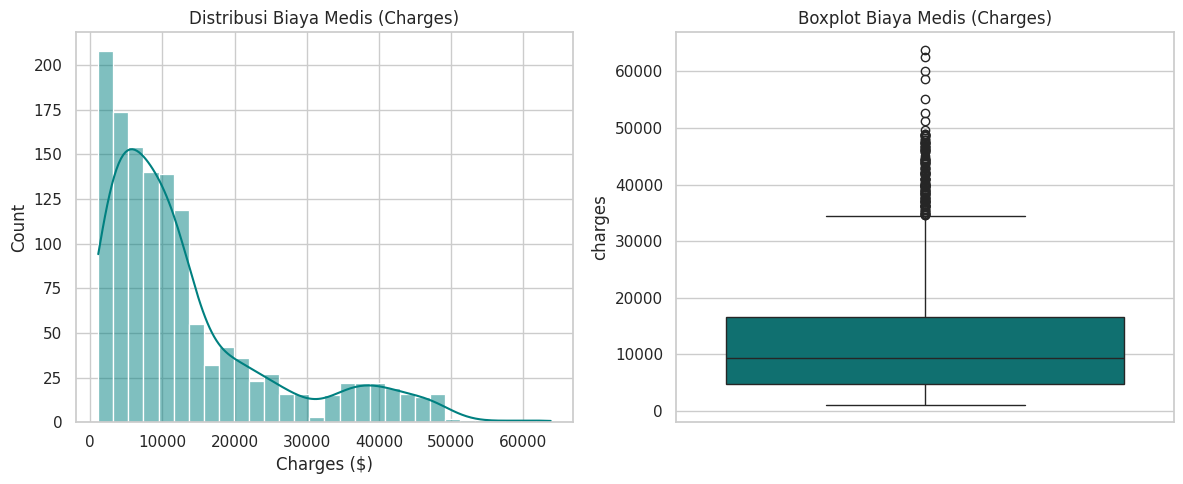

In [29]:
# 1. Distribusi Variabel Target (charges)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['charges'], kde=True, color='teal')
plt.title('Distribusi Biaya Medis (Charges)')
plt.xlabel('Charges ($)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['charges'], color='teal')
plt.title('Boxplot Biaya Medis (Charges)')

plt.tight_layout()
plt.show()

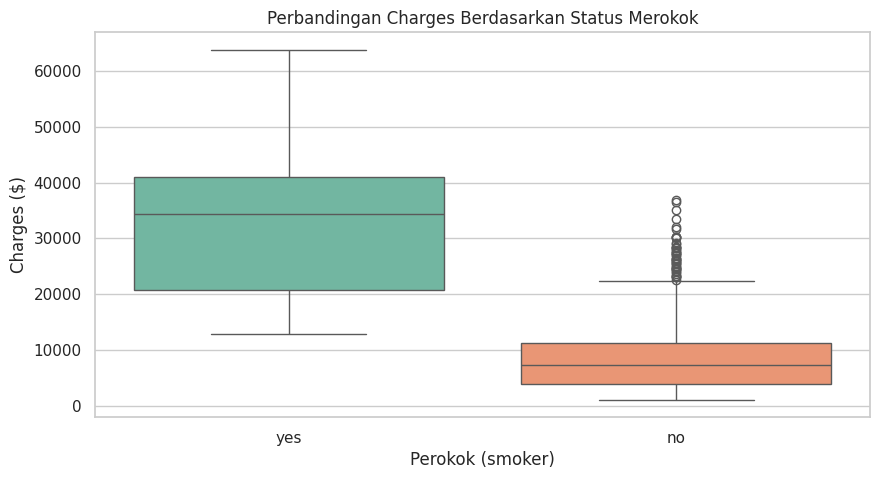

In [30]:
# 2. Pengaruh Status Merokok (smoker) terhadap Charges
plt.figure(figsize=(10, 5))
sns.boxplot(x='smoker', y='charges', data=df, palette='Set2')
plt.title('Perbandingan Charges Berdasarkan Status Merokok')
plt.xlabel('Perokok (smoker)')
plt.ylabel('Charges ($)')
plt.show()

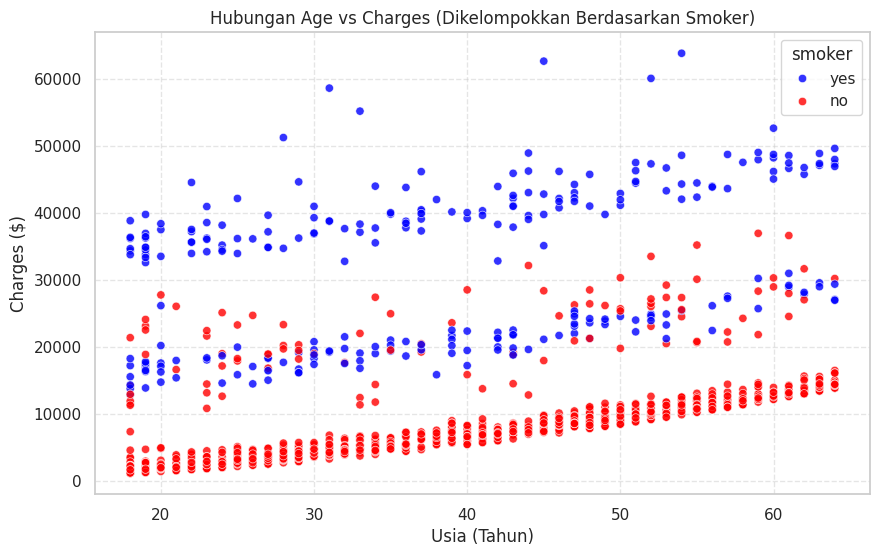

In [31]:
# 3. Hubungan Usia (Age) vs Charges dibedakan oleh Smoker
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, alpha=0.8, palette=['blue', 'red'])
plt.title('Hubungan Age vs Charges (Dikelompokkan Berdasarkan Smoker)')
plt.xlabel('Usia (Tahun)')
plt.ylabel('Charges ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

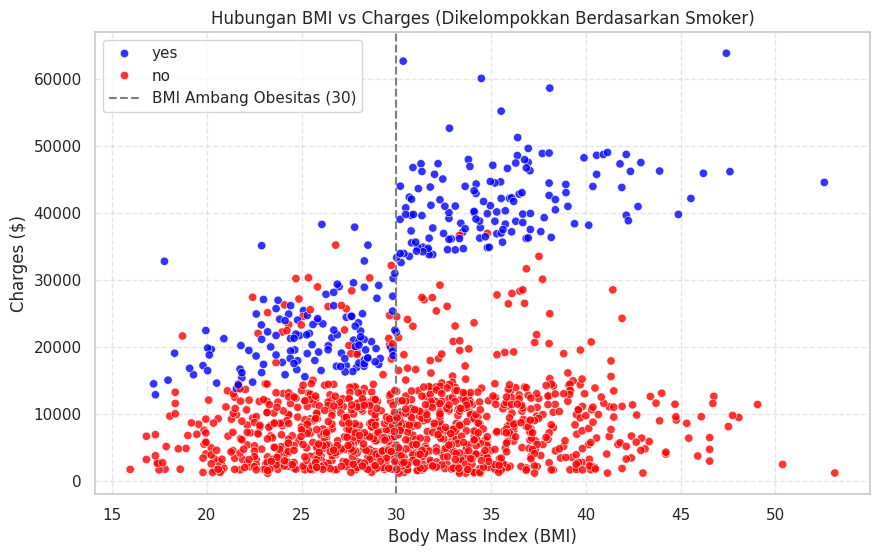

In [32]:
# 4. Hubungan BMI vs Charges dibedakan oleh Smoker
plt.figure(figsize=(10, 6))
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, alpha=0.8, palette=['blue', 'red'])
plt.axvline(30, color='gray', linestyle='--', label='BMI Ambang Obesitas (30)')
plt.title('Hubungan BMI vs Charges (Dikelompokkan Berdasarkan Smoker)')
plt.xlabel('Body Mass Index (BMI)')
plt.ylabel('Charges ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Dari visualisasi di atas terlihat pola yang sangat jelas:
- Peserta yang **merokok (`smoker=yes`)** memiliki biaya medis (`charges`) yang jauh lebih tinggi secara signifikan.
- Pada kelompok perokok yang memiliki BMI $\ge 30$ (obesitas), biaya medis melonjak drastis hingga lebih dari $30,000–$40,000.

## Langkah 4: Preprocessing Data (Encoding Variabel Kategorikal)
Variabel bertipe kategorikal (`sex`, `smoker`, `region`) diubah menjadi variabel biner / numerik menggunakan **One-Hot Encoding** (`pd.get_dummies` dengan `drop_first=True` untuk menghindari jebakan multikolinieritas / *dummy variable trap*).

In [33]:
# Encoding variabel kategorikal
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)
print("Data setelah encoding (5 baris pertama):")
df_encoded.head()

Data setelah encoding (5 baris pertama):


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


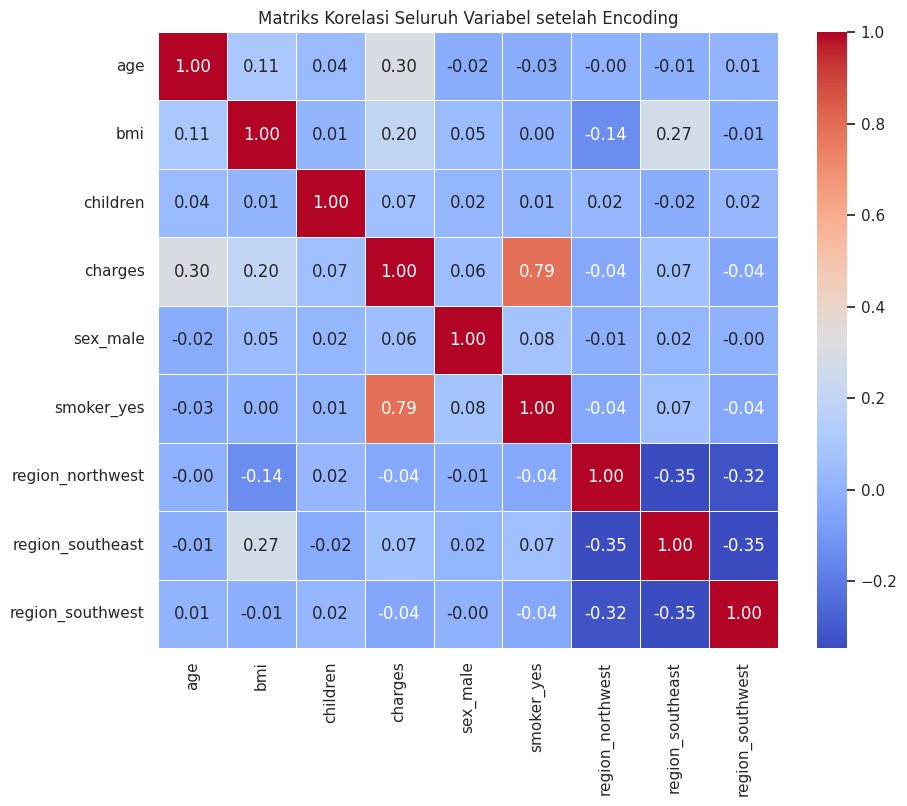

In [34]:
# Heatmap korelasi setelah encoding
plt.figure(figsize=(10, 8))
sns.heatmap(df_encoded.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Matriks Korelasi Seluruh Variabel setelah Encoding')
plt.show()

Dari matriks korelasi, variabel `smoker_yes` memiliki nilai korelasi tertinggi terhadap target `charges` ($r = 0.79$), diikuti oleh `age` ($r = 0.30$) dan `bmi` ($r = 0.20$).

## Langkah 5: Pembagian Data Latih dan Uji (Train-Test Split)

In [35]:
# Memisahkan fitur X dan target y
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

# Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Dimensi X_train : {X_train.shape}")
print(f"Dimensi X_test  : {X_test.shape}")
print(f"Dimensi y_train : {y_train.shape}")
print(f"Dimensi y_test  : {y_test.shape}")

Dimensi X_train : (1070, 8)
Dimensi X_test  : (268, 8)
Dimensi y_train : (1070,)
Dimensi y_test  : (268,)


## Langkah 6: Feature Scaling (Standardisasi)

In [36]:
# Inisialisasi StandardScaler
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Scaling fitur X
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Scaling target y (khusus untuk SVR)
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel()

print("Feature scaling berhasil dilakukan.")

Feature scaling berhasil dilakukan.


## Langkah 7: Pemodelan

In [37]:
# 1. Multiple Linear Regression (MLR)
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

# Prediksi MLR pada data uji
y_pred_mlr = mlr_model.predict(X_test)

# Menampilkan koefisien MLR
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': mlr_model.coef_
}).sort_values(by='Coefficient', ascending=False)

print(f"MLR Intercept: {mlr_model.intercept_:.2f}")
print("\nKoefisien Regresi Linier:")
display(coef_df)

MLR Intercept: -11931.22

Koefisien Regresi Linier:


,Feature,Coefficient
4,smoker_yes,23651.128856
2,children,425.278784
1,bmi,337.092552
0,age,256.975706
3,sex_male,-18.591692
5,region_northwest,-370.677326
6,region_southeast,-657.864297
7,region_southwest,-809.799354


In [38]:
# 2. Support Vector Regression (SVR)
svr_model = SVR(kernel='rbf', C=100.0, epsilon=0.1)
svr_model.fit(X_train_scaled, y_train_scaled)

# Prediksi SVR pada data uji (skala scaled)
y_pred_svr_scaled = svr_model.predict(X_test_scaled)

# Mengembalikan hasil prediksi ke skala asli dolar ($)
y_pred_svr = scaler_y.inverse_transform(y_pred_svr_scaled.reshape(-1, 1)).ravel()
print("SVR Model berhasil dilatih dan diprediksi.")

SVR Model berhasil dilatih dan diprediksi.


## Langkah 8: Evaluasi dan Perbandingan Performa Model

In [39]:
# Fungsi untuk menghitung metrik evaluasi
def evaluate_model(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    return {'R2': r2, 'MAE ($)': mae, 'MSE': mse, 'RMSE ($)': rmse}

# Hitung metrik untuk MLR dan SVR
mlr_metrics = evaluate_model(y_test, y_pred_mlr)
svr_metrics = evaluate_model(y_test, y_pred_svr)

# Membuat DataFrame Ringkasan Hasil
eval_df = pd.DataFrame([mlr_metrics, svr_metrics], index=['Multiple Linear Regression', 'Support Vector Regression (SVR)'])
eval_df['R2'] = eval_df['R2'].map('{:.4f}'.format)
eval_df['MAE ($)'] = eval_df['MAE ($)'].map('{:,.2f}'.format)
eval_df['MSE'] = eval_df['MSE'].map('{:,.2f}'.format)
eval_df['RMSE ($)'] = eval_df['RMSE ($)'].map('{:,.2f}'.format)

print("=== TABEL PERBANDINGAN EVALUASI MODEL ===")
display(eval_df)

=== TABEL PERBANDINGAN EVALUASI MODEL ===


,R2,MAE ($),MSE,RMSE ($)
Multiple Linear Regression,0.7836,"4,181.19","33,596,915.85","5,796.28"
Support Vector Regression (SVR),0.8340,"2,777.40","25,769,373.99","5,076.35"


## Langkah 9: Visualisasi Hasil Prediksi dan Analisis Residual

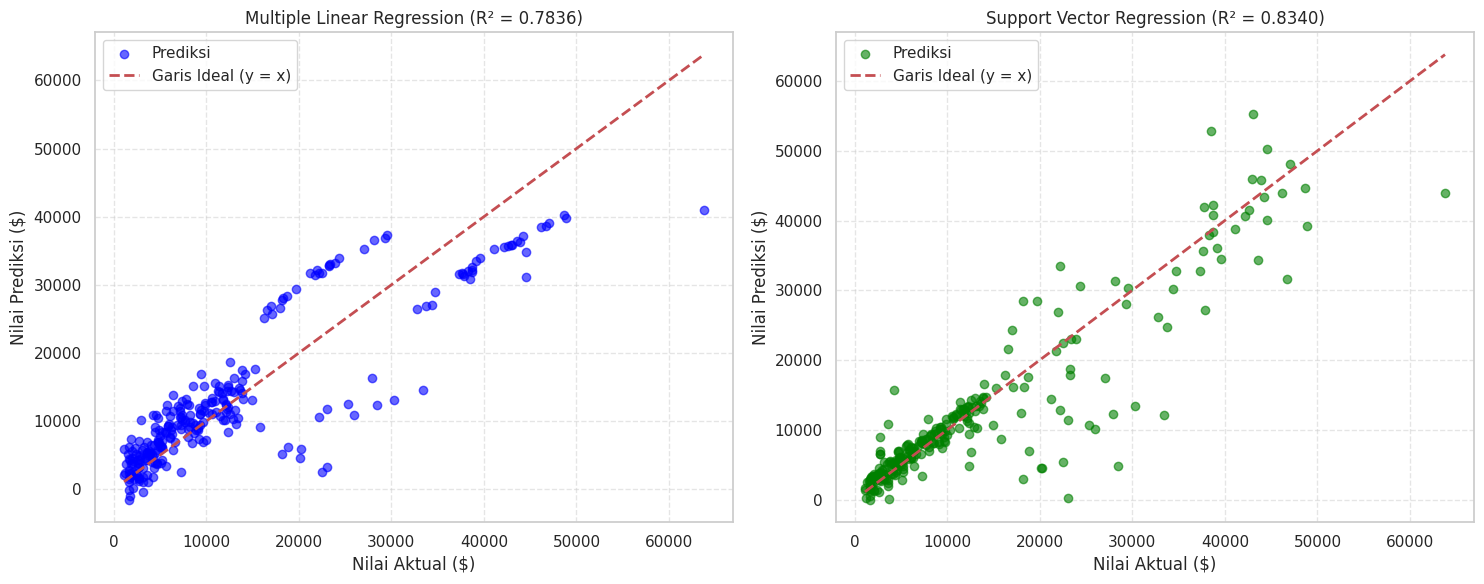

In [40]:
# 1. Scatter Plot Aktual vs Prediksi
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Multiple Linear Regression
axes[0].scatter(y_test, y_pred_mlr, color='blue', alpha=0.6, label='Prediksi')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Ideal (y = x)')
axes[0].set_title(f'Multiple Linear Regression (R² = {r2_score(y_test, y_pred_mlr):.4f})')
axes[0].set_xlabel('Nilai Aktual ($)')
axes[0].set_ylabel('Nilai Prediksi ($)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Support Vector Regression
axes[1].scatter(y_test, y_pred_svr, color='green', alpha=0.6, label='Prediksi')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Ideal (y = x)')
axes[1].set_title(f'Support Vector Regression (R² = {r2_score(y_test, y_pred_svr):.4f})')
axes[1].set_xlabel('Nilai Aktual ($)')
axes[1].set_ylabel('Nilai Prediksi ($)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

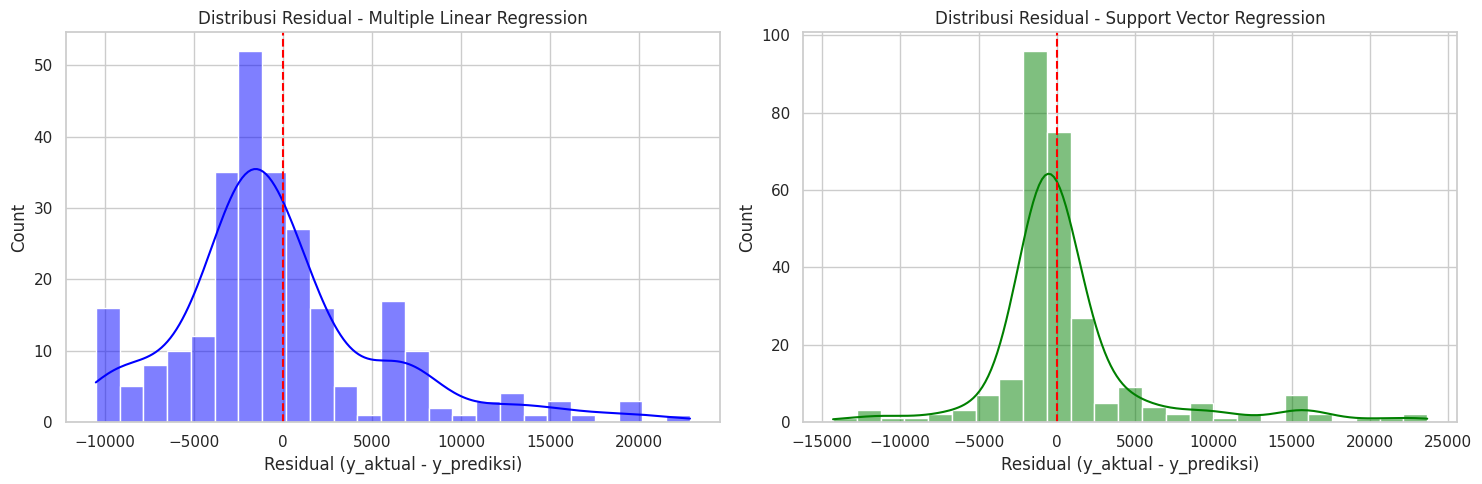

In [41]:
# 2. Residual Distribution Plot
residual_mlr = y_test - y_pred_mlr
residual_svr = y_test - y_pred_svr

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(residual_mlr, kde=True, ax=axes[0], color='blue', bins=25)
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title('Distribusi Residual - Multiple Linear Regression')
axes[0].set_xlabel('Residual (y_aktual - y_prediksi)')

sns.histplot(residual_svr, kde=True, ax=axes[1], color='green', bins=25)
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Distribusi Residual - Support Vector Regression')
axes[1].set_xlabel('Residual (y_aktual - y_prediksi)')

plt.tight_layout()
plt.show()

## Langkah 10: Analisis Hasil dan Pembahasan

### Kesimpulan Akhir:
1. Variabel terpenting dalam penentuan biaya medis personal adalah status merokok, indeks massa tubuh (BMI), dan usia.
2. Pemilihan teknik pemodelan non-linier seperti Support Vector Regression terbukti lebih efektif dan akurat daripada regresi linier murni untuk dataset medis dengan kompleksitas interaksi fitur seperti `insurance.csv`.